# Deconvolution and Decomposition of Human Kidney Cancer Core Data using Spotiphy
- Based on [Spotiphy Tutorial](https://github.com/jyyulab/Spotiphy/blob/main/tutorials/Spotiphy_tutorial_visium.ipynb)
- Last update: Dec 15th 2025

## Contents
1. [Environment Setup: Package Installation and Loading](#Install)
2. [Data Preparation: Loading and Processing](#Load-data)
3. [Deconvolution: Marker Gene Selection and scRNA Reference Construction](#Marker)
4. [Deconvolution: Cellular Proportion Estimation](#Deconvolution)
5. [Deconvolution: Cell Number Estimation Using Segmentation](#Segmentation)
6. [Decomposition: Expression Breakdown of Each Spot to Single-cell Resolution](#Decomposition)
7. [Imputation: Creation of Pseudo Single-cell resolution Image](#Pseudo_image)

In [1]:
import sys
import os
import spotiphy
import pickle
import numpy as np
import pandas as pd
import matplotlib as mpl
import scanpy as sc
import torch
import cv2

bioimageio_utils.py (2): pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
2025-11-03 12:27:19.359178: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-11-03 12:27:19.389228: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-11-03 12:27:19.389275: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-11-03 12:27:19.408295: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is opt

In [2]:
os.environ["CUDA_VISIBLE_DEVICES"] = "1" 
import tensorflow as tf

In [3]:
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available:  1


In [4]:
from pathlib import Path
from gctsvg.preprocessing import common, image, kidneycancer

decorators.py (246): nopython is set for njit and is ignored


Specify the output folder.

In [5]:
results_folder = "Spotiphy_Result/Human Kidney Cancer Core/"
if not os.path.exists(results_folder):
    # Create result folder if it does not exist
    os.makedirs(results_folder)

## Data Preparation: Loading and Processing <a id=Load-data></a>

Check if the example datasets exist. If not, download them from Github.

In [6]:
data_dir = Path('data_repo/Human Kidney Cancer')
output_dir = Path(results_folder)
patient_id = 'PD47171'

In [7]:
# if not os.path.exists("ST checkpoints/Human Kidney Cancer"):
#     os.makedirs("ST checkpoints/Human Kidney Cancer")

Load the scRNA data, visium data and the corresponding H&E staining image.

In [8]:
adata_sc = sc.read_h5ad(data_dir / "RCC_upload_final_raw_counts.h5ad")
adata_st_core = sc.read_h5ad(data_dir / "visium_merge_core_upload.h5ad")

In [9]:
# Extract data of patient PD47171
adata_sc = kidneycancer.extract_sc_patient_data(adata_sc, patient_id)
adata_st_core = kidneycancer.extract_st_patient_data(adata_st_core, patient_id)

In [10]:
# Format data to use ENSEMBL gene id as index
# necessary to align indexes of st and sc datasets
adata_sc = common.use_ensembl_gene_ids(adata_sc, 'name')

anndata.py (1756): Variable names are not unique. To make them unique, call `.var_names_make_unique`.


In [11]:
image

<module 'gctsvg.preprocessing.image' from '/workspace/ct-SVG/gctsvg/preprocessing/image.py'>

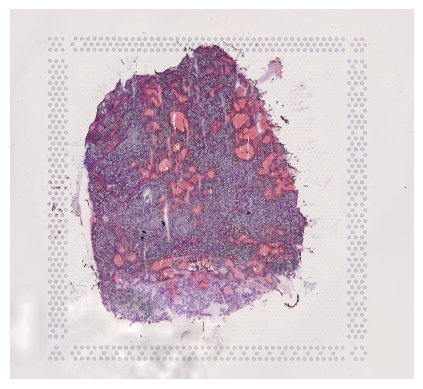

In [12]:
# Get ST image
img = image.get_image(adata_st_core, scale=True)

# Plot without axes
mpl.pyplot.imshow(img)
mpl.pyplot.axis('off')  # Remove axis ticks and labels
mpl.pyplot.show()

In [13]:
if not Path.exists(output_dir):
    Path.mkdir(output_dir, parents=True)
    
adata_sc.write(output_dir / 'Human Kidney Cancer scRNA Ref.h5ad')
adata_st_core.write(output_dir / 'Human Kidney Cancer Core.h5ad')
img.save(output_dir / 'Human Kidney Cancer Core.tif')

In [14]:
adata_sc = sc.read_h5ad(output_dir / 'Human Kidney Cancer scRNA Ref.h5ad')
adata_st_core = sc.read_h5ad(output_dir / 'Human Kidney Cancer Core.h5ad')
img = cv2.imread(output_dir / 'Human Kidney Cancer Core.tif')
# img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
# Another opinion for loading Visium data is to use the following function and point the directory to the 10x Visium raw data folder.
# adata_st = sc.read_visium("data/ST_mouse_brain/outs")

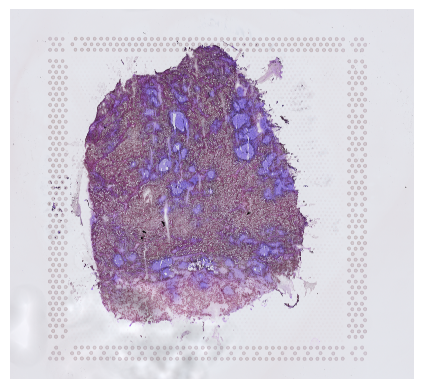

In [15]:
# Display image
mpl.pyplot.imshow(img)
mpl.pyplot.axis('off')
mpl.pyplot.show()

`key_type` refers to the annotation of scRNA data used for reference construction.
If modificationas are needed, such as merging several cell subtypes into a general cell type, use the following code:
```python
# Define the cell types to merge and the new cell type name
types_to_merge = ['subtype1A', 'subtype1B', 'subtype1C', 'subtype1D']
new_type = 'Type1'

# Merge the specified cell types into the new type
adata_sc.obs['cellType'] = adata_sc.obs['cellType'].replace(types_to_merge, new_type)
```

In [16]:
key_type = "broad_type"
type_list = sorted(list(adata_sc.obs[key_type].unique().astype(str)))
print(f"There are {len(type_list)} cell types: {type_list}")
adata_st_core.var_names_make_unique()

There are 12 cell types: ['B-cell', 'EC', 'Epi_PT', 'Epi_non-PT', 'Fibro', 'Mast', 'Myeloid', 'NK', 'Plasma', 'RCC', 'T-cell', 'pDC']


Convert the spatial coordinates into integer values.

In [17]:
adata_st_core.obsm["spatial"] = adata_st_core.obsm["spatial"].astype(np.int32)
# print(adata_st.obsm['spatial'])

Verify all inputs carefully before proceeding.

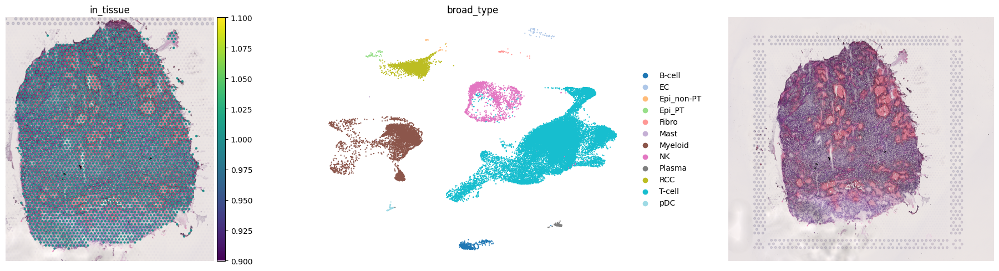

In [18]:
fig, axs = mpl.pyplot.subplots(1, 3, figsize=(20, 5))
sc.pl.spatial(adata_st_core, color="in_tissue", frameon=False, show=False, ax=axs[0])
sc.pl.umap(adata_sc, color=key_type, size=10, frameon=False, show=False, ax=axs[1])
axs[2].imshow(
    img[:, :, [ 2, 1, 0]]
)  # In default, cv2 uses BGR. So we convert BGR to RGB.
axs[2].axis("off")
mpl.pyplot.tight_layout()
mpl.pyplot.savefig(
    output_dir / "figurepath+figurename.jpg", bbox_inches="tight", dpi=400
)

## Deconvolution: Marker Gene Selection and scRNA Reference Construction <a id="Marker"></a>

Initialize the spatial transcriptomics and scRNA data. Specifically,
* `adata_sc` and `adata_st` are normalized
* cells and genes in `adata_sc` are filtered
* only the common genes shared by `adata_sc` and `adata_st` are kept

In [19]:
adata_sc, adata_st_core = spotiphy.initialization(adata_sc, adata_st_core, verbose=1)

Convert expression matrix to array: 2.35s
Normalization: 2.73s
Filtering: 3.11s
Find common genes: 0.04s


Select marker genese based on pairwise statistical tests. The selected marker genes are saved as a CSV file.

Users can adjust the following arguments:
- `n_select`: the maximum number of marker genese select for each cell type
- `threshold_p`: threshold of the $p$-value to be considered significant 
- `threshold_fold`: threshold of the fold-change to be considered significant
- `q`: Since more than one $p$-values are obtained in using the pairwise tests, we only consider the $p$-value at quantile `q`. For additional details, please refer to the supplementary material of the paper.
- `return_dict`: Whether return a dictionary representing the marker genes selected for each cell type, or just return the list of all selected marker genes.

The parameters specified in the following code block provide a good starting point.

In [20]:
marker_gene_dict = spotiphy.sc_reference.marker_selection(
    adata_sc,
    key_type=key_type,
    return_dict=True,
    n_select=50,
    threshold_p=0.1,
    threshold_fold=1.5,
    q=0.15,
)
marker_gene = []
marker_gene_label = []
for type_ in type_list:
    marker_gene.extend(marker_gene_dict[type_])
    marker_gene_label.extend([type_] * len(marker_gene_dict[type_]))
marker_gene_df = pd.DataFrame({"gene": marker_gene, "label": marker_gene_label})
marker_gene_df.to_csv(f"{results_folder}marker_gene.csv")
# Filter scRNA and spatial matrices with marker genes
adata_sc_marker = adata_sc[:, marker_gene]
adata_st_core_marker = adata_st_core[:, marker_gene]

Construct the single-cell reference and visualize selected marker genes with heatmaps.

Adjust parameters in the previous step as needed to optimize marker gene selection:
- If several cell types are very similar (e.g., T cell subtypes), try setting `q=0.3` or adjust accordingly.
- If there are limited marker genes for each cell type, try setting `threshold_fold=1.2` or adjust as needed.

12it [00:00, 369.63it/s]


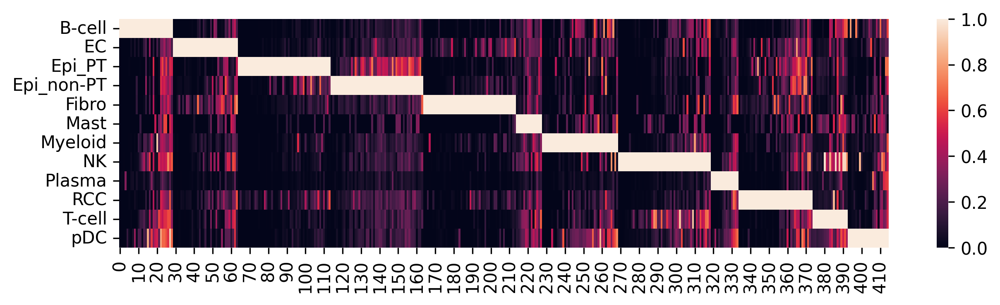

In [21]:
sc_ref = spotiphy.construct_sc_ref(adata_sc_marker, key_type=key_type)
spotiphy.sc_reference.plot_heatmap(
    adata_sc_marker, key_type, save=True, out_dir=results_folder
)

Another opinion will be input your customized marker gene list. Use the following code:

In [22]:
# marker_gene = pd.read_csv(results_folder+'customized_marker_genes.csv', header=0)

## Deconvolution: Cellular Proportion Estimation <a id="Deconvolution"></a>

For performing the deconvolution, we calculate the posterior distribution of certain parameters within a probabilistic generative model using [`Pyro`](https://pyro.ai/).

Parameters of the function `estimation_proportion`:
- `X`: Spatial transcriptomics data. n_spot*n_gene
- `adata_sc`: scRNA data (Anndata).
- `sc_ref`: Single cell reference. n_type*n_gene
- `type_list`: List of the cell types.
- `key_type`: Column name of the cell types in adata_sc.
- `batch_prior`: Parameter involved in the prior distribution of the batch effect factors. It is recommended to select from $[1,2]$.
- `n_epoch`: Number of training epoch.

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8000/8000 [15:07<00:00,  8.82it/s]


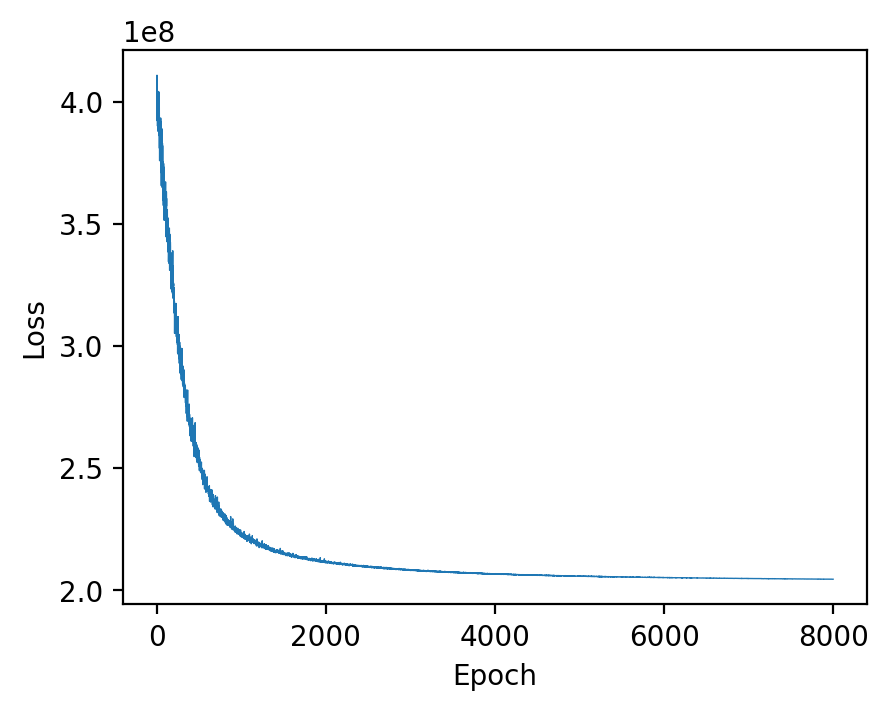

1048041738.py (14): Trying to modify attribute `.obs` of view, initializing view as actual.


In [24]:
device = "cuda" if torch.cuda.is_available() else "cpu"
X = np.array(adata_st_core_marker.X)
cell_proportion = spotiphy.deconvolution.estimation_proportion(
    X,
    adata_sc_marker,
    sc_ref,
    type_list,
    key_type,
    n_epoch=8000,
    plot=True,
    batch_prior=1,
    device=device,
)
adata_st_core.obs[type_list] = cell_proportion
# Save the cellular proportions for future usage
np.save(results_folder + "proportion.npy", cell_proportion)
np.savetxt(results_folder + "proportion.csv", adata_st_core.obs[type_list], delimiter=",")

Generate heatmaps of cellular proportions.

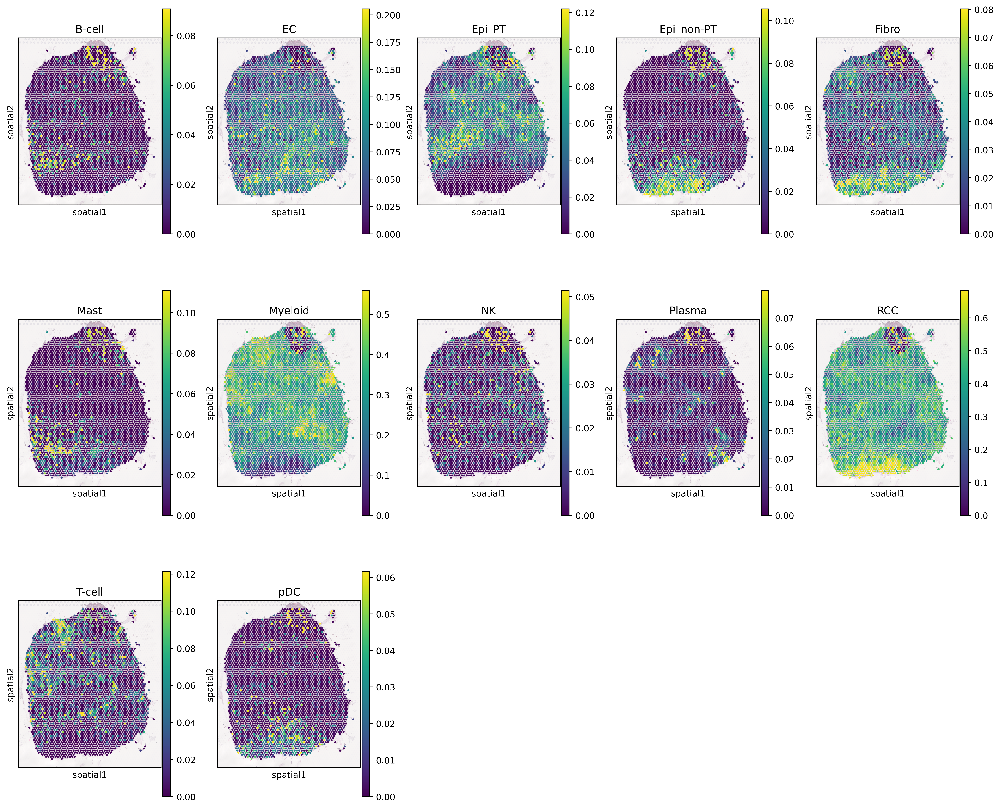

In [46]:
vmax = np.quantile(adata_st_core.obs[type_list].values, 0.98, axis=0)
vmax[vmax < 0.05] = 0.05
with mpl.rc_context(
    {"figure.figsize": [3, 5], "figure.dpi": 400, "xtick.labelsize": 0}
):
    ax = sc.pl.spatial(
        adata_st_core,
        cmap="viridis",
        color=type_list,
        img_key="hires",
        vmin=0,
        vmax=list(vmax),
        size=1.3,
        show=False,
        ncols=5,
        alpha_img=0.4,
    )
    ax[0].get_figure().savefig(f"{results_folder}Spotiphy_deconvolution.jpg")

## Deconvolution: Cell Number Estimation Using Segmentation <a id="Segmentation"></a>
`Stardist` package is used to segment nuclei from H&E staining images, after which the number of nuclei in each spot is counted. Note that the image and segmentation step is not required if only deconvolution results are needed.

Parameters used in function `Segmentation`:

- `img` (numpy.ndarray): Three channel stained image. In default, it should be hematoxylin and eosin (H&E) stained image.
- `spot_center`: Coordinates of the center of the spots.
- `out_dir`: Output directory.
- `Prob_thresh`: `nms_thresh`: Two thresholds used in Stardist. User should adjust these two thresholds based on the segmentation results. More details can be found [here](https://squidpy.readthedocs.io/en/stable/notebooks/tutorials/tutorial_stardist.html).
- `spot_radius`: Radius of the spots. In the example image, it should be 36.5 in pixel (55um).
- `n_tiles`: Out of memory (OOM) errors can occur if the input image is too large. To avoid this problem, the input image is broken up into (overlapping) tiles that are processed independently and re-assembled. In default, we break the image into 8*8 tiles.
- `enhancement`: An image enhancement feature for pre-processing input images. Users can enable or disable this feature by setting the parameter to `True` or `False`. It is recommended to compare the segmentation outputs with enhancement ON and OFF. Preliminary comparisons indicate that enhanced HE images can significantly reduce the false negative rate of StarDist, allowing for the detection of more accurate nuclei.


In [25]:
img.shape

# (9859, 10751, 3)
# (4100, 2600, 3)

(9859, 10751, 3)

In [26]:
if not os.path.exists(f"{results_folder}segmentation/"):
    os.makedirs(f"{results_folder}segmentation/")

# (16, 16,1) -> 25438126080
# (4, 8,1) -> 938606592
# (6, 9, 1) -> 938606592
# 25438126080

segmentation = spotiphy.segmentation.Segmentation(
    img[:, :, [2, 1, 0]],
    adata_st_core.obsm["spatial"],
    n_tiles=(8, 8, 1),
    out_dir=f"{results_folder}segmentation/",
    enhancement=True,
)
segmentation.segment_nucleus(save=True)
n_cell_df = segmentation.n_cell_df
# Save the segmentation for future usage
df = pd.DataFrame(n_cell_df)
df.to_csv(f"{results_folder}segmentation/n_cell_per_spot.csv", index=False)

Suppress the output of tensorflow prediction for tensorflow version 2.16.2>=2.9.0.
Found model '2D_versatile_he' for 'StarDist2D'.


2025-11-03 14:12:59.968895: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1928] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 17611 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3090, pci bus id: 0000:af:00.0, compute capability: 8.6


Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.692478, nms_thresh=0.3.


I0000 00:00:1762179182.238345 1547207 service.cc:145] XLA service 0x7f2e4400b0c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1762179182.238418 1547207 service.cc:153]   StreamExecutor device (0): NVIDIA GeForce RTX 3090, Compute Capability 8.6
2025-11-03 14:13:02.282879: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2025-11-03 14:13:05.187561: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907
2025-11-03 14:13:10.645600: W external/local_xla/xla/service/gpu/nvptx_compiler.cc:742] The NVIDIA driver's CUDA version is 12.0 which is older than the ptxas CUDA version (12.3.107). Because the driver is older than the ptxas version, XLA is disabling parallel compilation, which may slow down compilation. You should update your NVIDIA driver or use the NVIDIA-provided CUDA forward compatibility

Plot a small section of the segmented results for examination.

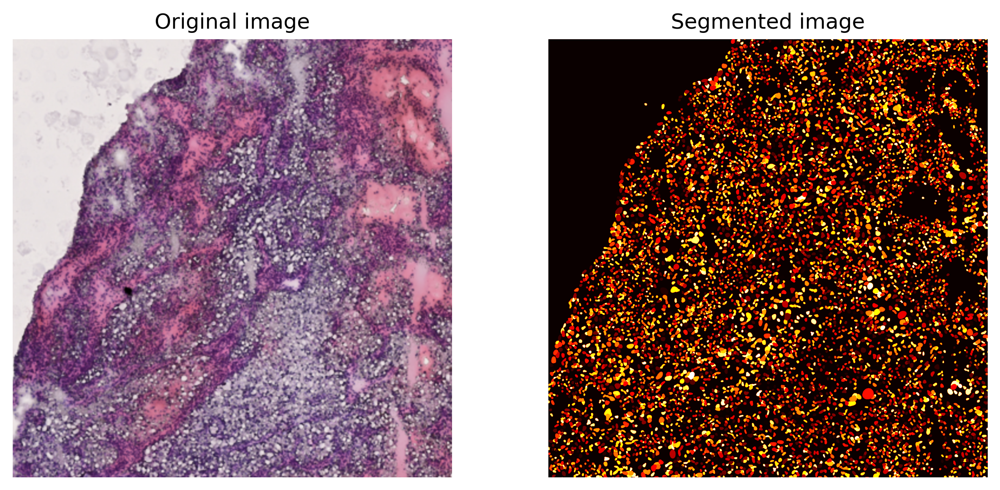

In [45]:
segmentation.plot(
    save=True,
    crop=(2000, 4000, 2000, 4000),
    path=results_folder + "segmentation/segmentation_sample.jpg",
)

## Decomposition: Expression Breakdown of Each Spot to Single-cell Resolution <a id="Decomposition"></a>

To decompose all genes in the spatial transcriptomics data, both scRNA-seq data and spatial transcriptomics data must be reloaded.
`n_cell` represents the number of cells in each spot, with four opinions available:

- `n_cell_df['cell_count'].values`. The default setting, which uses the number of nuclei derived from segmentation results.
- `estimate`. Estimates the number of cells based on the total counts for each spot.
- `[fixed_value] * len(adata_st_orig)`. A user defined `[fixed_value]` is applied as the cell number for all spots.
- `None`. Assums that a cell type does not exist in a spot unless its proportion exceeds the `threshold`.

For more details, please refer to the [document](https://jyyulab.github.io/Spotiphy/deconvolution.html#deconvolution.decomposition).

In [31]:
adata_sc_orig = sc.read_h5ad(output_dir / 'Human Kidney Cancer scRNA Ref.h5ad')
adata_st_orig = sc.read_h5ad(output_dir / 'Human Kidney Cancer Core.h5ad')
adata_st_orig.var_names_make_unique()

In [32]:
adata_st_orig

AnnData object with n_obs × n_vars = 3008 × 36601
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499410', 'mean_counts-6800STDY12499410', 'log1p_mean_counts-6800STDY12499410', 'pct_dropout_by_counts-6800STDY12499410', 'total_counts-6800STDY12499410', 'log1p_total_counts-6800STDY12499410'
    uns: 'sample_colors', 'spatial'
    obsm: 'spatial'

In [33]:
# Read in the saved segmentation results.
# n_cell_df = pd.read_csv(results_folder+'segmentation/n_cell_df.csv', header=0)
n_cell = n_cell_df["cell_count"].values
adata_st_decomposed = spotiphy.deconvolution.decomposition(
    adata_st_orig,
    adata_sc_orig,
    key_type,
    cell_proportion,
    save=True,
    out_dir=results_folder,
    verbose=1,
    spot_location=adata_st_orig.obsm["spatial"],
    filtering_gene=True,
    n_cell=n_cell,
    filename="ST_decomposition.h5ad",
)

Prepared proportion data. Time use 0.23
Initialized scRNA and ST data. Time use 8.12


12it [00:00, 17.48it/s]


Processed scRNA and ST data. Time use 5.56
Decomposition complete. Time use 5.17
Constructed ST decomposition data file. Time use 3.26
Saved file to output folder. Time use 23.07


## Imputation: Creation of Pseudo Single-cell resolution Image <a id="Pseudo_image"></a>

The H&E staining image only highlights nuclei, we first infer the boundary of each cell. Specifically, the area of each cell is gradually expanded outward from the center of its nucleus. The expansion stops when one of the following conditions is met:
- The cell area exceeds `max_area`.
- The surrounding neighborhood is fully occupied by other cells.
- The maximum distance from the cell boundary to the nucleus center exceeds `max_dist`.
- `delta` represent the incremental expansion distance in each iteration.

In [34]:
search_direction = [
    [1, 0],
    [0, 1],
    [-1, 0],
    [0, -1],
    [2, 0],
    [0, 2],
    [-2, 0],
    [0, -2],
    [1, 1],
    [-1, 1],
    [-1, -1],
    [1, -1],
]
boundary_dict = spotiphy.segmentation.cell_boundary(
    segmentation.nucleus_df[["x", "y"]].values,
    img_size=img.shape[:2],
    max_dist=25,
    max_area=580,
    verbose=0,
    search_direction=search_direction,
    delta=2,
)
# Save the dictionary of the cell boundaries for future usage
with open(results_folder + f"segmentation/boundary_dict.pkl", "wb") as file:
    pickle.dump(boundary_dict, file)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9859/9859 [00:53<00:00, 182.77it/s]


Assign cell types to nuclei in the spatial image through the following steps:
- Function `proportion_to_count`: Calculate the count of each cell type based on segmentation results and the estimated cellular proportions.
- Function `assign_type_spot`: Assign cell types to nuclei within the spatial spots.
- Function `cell_proportion_smooth`: Allocate cell types to nuclei located outside the spatial spots.

In [35]:
cell_number = spotiphy.deconvolution.proportion_to_count(
    cell_proportion, n_cell_df["cell_count"].values, multiple_spots=True
)
segmentation.nucleus_df = spotiphy.deconvolution.assign_type_spot(
    segmentation.nucleus_df, segmentation.n_cell_df, cell_number, type_list
)
segmentation.nucleus_df, cell_proportion_smooth = (
    spotiphy.deconvolution.assign_type_out(
        segmentation.nucleus_df,
        cell_proportion,
        segmentation.spot_center,
        type_list,
        band_width=150,
    )
)

Define the class `plot_visium` to generate the pseudo image. Plot the image legend.

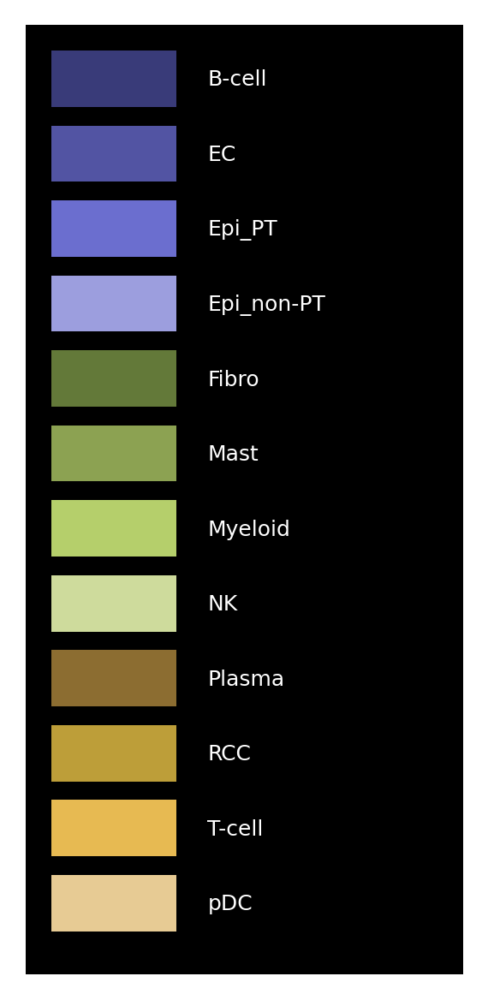

In [36]:
plot_visium = spotiphy.plot.Plot_Visium(
    segmentation=segmentation, boundary_dict=boundary_dict, type_list=type_list
)
plot_visium.plot_legend(save=f"{results_folder}legend.png")

Generate the pseudo image by specifying the following arguments:
- `shape`: Defines the shape used for cells in the image. Opinions include `cell`, `nucleus`, or `circle`.
- `cell`: Indicates which group of cells to include in the image. Choose from `in`, `out`, or `both`.
- `boundary`: Indicates which group of boundaries to include in the image. Choose from `in`, `out`, `both` or `None`.

For example, to generate a pseudo image containing only cells inside the spatial spots, use the following settings.

Adding cells.


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9859/9859 [08:38<00:00, 19.01it/s]
12it [00:03,  3.12it/s]
74044it [00:00, 831923.98it/s]
100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 74044/74044 [00:00<00:00, 262178.97it/s]


Adding spots.
Saving the image.


[ WARN:0@10164.050] global loadsave.cpp:1063 imwrite_ Unsupported depth image for selected encoder is fallbacked to CV_8U.


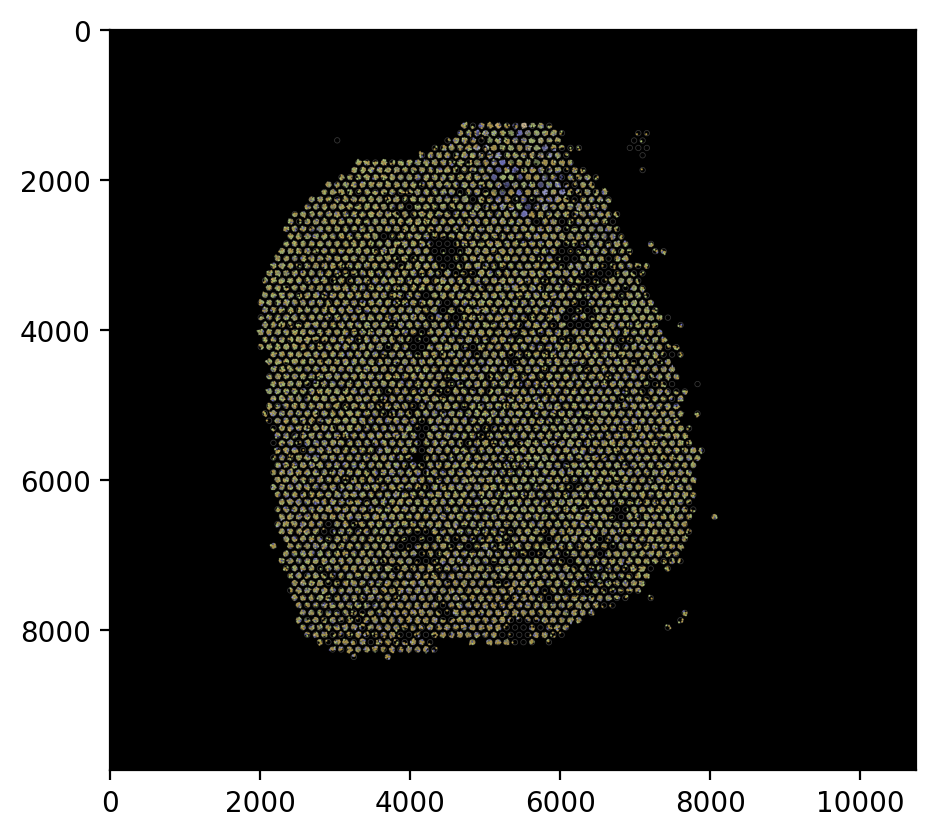

In [37]:
# To generate a pseudo image containing only cells inside the spatial spots, use the following settings.
plot_visium.plot(
    background=False,
    save=f"{results_folder}pseudo_image_in.png",
    spot_color=(200, 200, 200),
    shape="cell",
    cell="in",
    boundary="in",
    dpi=200,
)

Adding cells.


74044it [00:00, 150102.83it/s]
100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 74044/74044 [00:00<00:00, 1254252.87it/s]


Adding spots.
Saving the image.


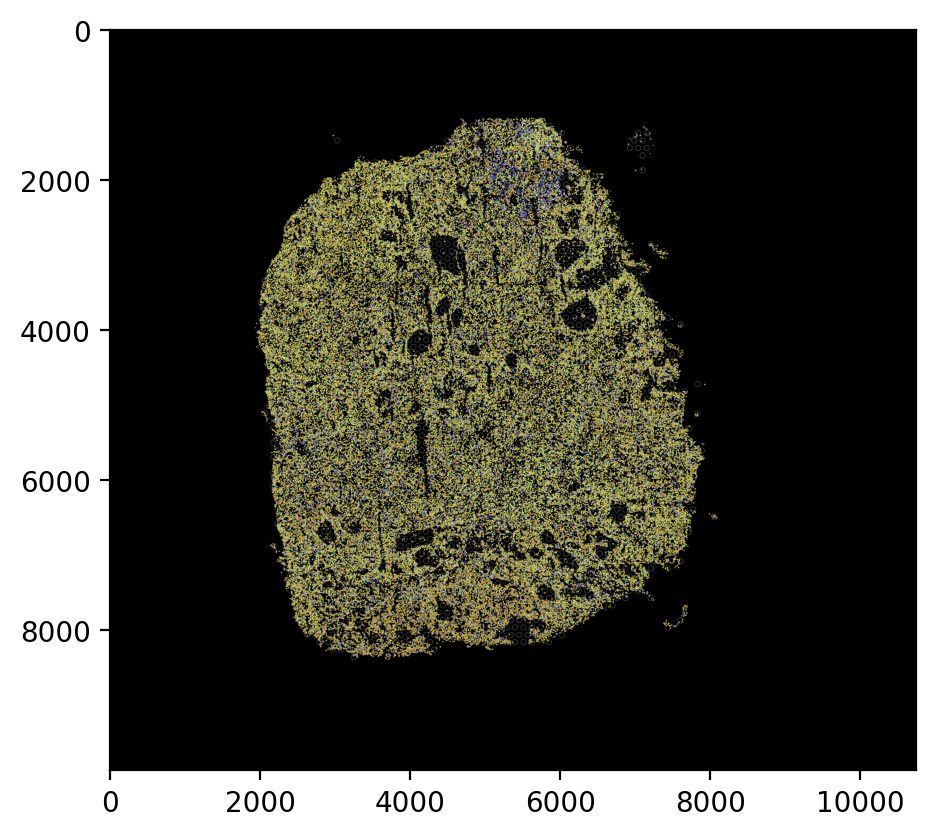

In [38]:
# To display all cells as circles without the cell boundaries, use the following settings.
plot_visium.plot(
    background=False,
    save=f"{results_folder}pseudo_image_both_circle.png",
    spot_color=(200, 200, 200),
    shape="circle",
    cell="both",
    boundary=None,
    dpi=200,
)

In [39]:
with open(f"{results_folder}segmentation/segmentation.pkl", "wb") as file:
    pickle.dump(segmentation, file)

In [40]:
adata_st_orig

AnnData object with n_obs × n_vars = 3008 × 36601
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'donor_id', 'region'
    var: 'feature_types', 'genome', 'SYMBOL', 'mt', 'n_cells_by_counts-6800STDY12499410', 'mean_counts-6800STDY12499410', 'log1p_mean_counts-6800STDY12499410', 'pct_dropout_by_counts-6800STDY12499410', 'total_counts-6800STDY12499410', 'log1p_total_counts-6800STDY12499410'
    uns: 'sample_colors', 'spatial', 'cell_count'
    obsm: 'spatial'

In [41]:
adata_st_decomposed

AnnData object with n_obs × n_vars = 27723 × 10867
    obs: 'cell_type', 'spot_name', 'n_cell', 'location_x', 'location_y'
    uns: 'sample_colors', 'spatial', 'cell_count'

In [42]:
adata_st_orig.obsm['spatial'][:20]

array([[7431, 6191],
       [2741, 7073],
       [2177, 5500],
       [2402, 5893],
       [7147, 7273],
       [3250, 5402],
       [4041, 6386],
       [6356, 7665],
       [2742, 4910],
       [5287, 1864],
       [6132, 4716],
       [5000, 7861],
       [5622, 7763],
       [5454, 5699],
       [2741, 5697],
       [4382, 2257],
       [2517, 4124],
       [2910, 7761],
       [4718, 7369],
       [4775, 6681]])

In [43]:
adata_st_decomposed[680:685].obs

,cell_type,spot_name,n_cell,location_x,location_y
680,EC,6800STDY12499410_AGGCAGGGAGCGTACT-1,2,4436,7074
681,EC,6800STDY12499410_AGGCCCTAGAACGCCA-1,1,3080,5697
682,EC,6800STDY12499410_AGGCCTGAGAATCTCG-1,1,6639,7371
683,EC,6800STDY12499410_AGGCGGTTTGTCCCGC-1,1,2628,7073
684,EC,6800STDY12499410_AGGCTATGGTTAGCTT-1,1,3364,3829


In [44]:
adata_st_decomposed.obs[1000:1200]

,cell_type,spot_name,n_cell,location_x,location_y
1000,EC,6800STDY12499410_CAGAACTTAGCCCTCT-1,1,6470,6486
1001,EC,6800STDY12499410_CAGACACCGATCGCTG-1,1,4549,6484
1002,EC,6800STDY12499410_CAGACCTGTAAGTGTT-1,1,7262,4323
1003,EC,6800STDY12499410_CAGACGAACCTGATAC-1,1,4493,6190
1004,EC,6800STDY12499410_CAGAGACGGTCACCCA-1,1,4888,6288
...,...,...,...,...,...
1195,EC,6800STDY12499410_CCTATGTCCACTCCAC-1,3,6865,7371
1196,EC,6800STDY12499410_CCTATGTCCACTCCAC-1,3,6865,7371
1197,EC,6800STDY12499410_CCTCACCAATCTTGAC-1,1,3647,2945
1198,EC,6800STDY12499410_CCTCACCTTAGCATCG-1,1,7150,3930


In [47]:
segmentation.nucleus_df

,x,y,in_spot,cell_type
0,3852,2612,False,Myeloid
1,7638,4426,False,unknown
2,6922,6308,True,RCC
3,1610,4932,False,unknown
4,7802,5140,False,Epi_PT
...,...,...,...,...
74039,6338,7842,False,RCC
74040,4228,2616,False,RCC
74041,3576,4652,False,RCC
74042,4620,4518,False,RCC
